PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [1]:
import requests
import json
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
#ignore warnings
import warnings
warnings.filterwarnings("ignore")
import ScraperFC as sfc
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error


In [2]:
indexes=pd.read_csv('indexes_1524.csv')
epl_stats=pd.read_csv("stats_epl1524_processed.csv")


In [3]:
indexes

,date,id,home_team,away_team,home_score,away_score,season
0,2016-04-30 16:30:00,6768365,Arsenal,Norwich City,1,0,15/16
1,2016-05-01 11:00:00,6768337,Swansea City,Liverpool,3,1,15/16
2,2016-05-01 13:05:00,6768390,Manchester United,Leicester City,1,1,15/16
3,2016-05-01 15:30:00,6768392,Southampton,Manchester City,4,2,15/16
4,2016-05-02 19:00:00,6768354,Chelsea,Tottenham Hotspur,2,2,15/16
...,...,...,...,...,...,...,...
3415,2023-08-19 19:00:00,11352389,Manchester City,Newcastle United,1,0,23/24
3416,2023-08-20 13:00:00,11352337,Aston Villa,Everton,4,0,23/24
3417,2023-08-20 15:30:00,11352418,West Ham United,Chelsea,3,1,23/24
3418,2023-08-21 19:00:00,11352346,Crystal Palace,Arsenal,0,1,23/24


In [38]:
indexes['home_team'].unique()

array(['Arsenal', 'Swansea City', 'Manchester United', 'Southampton',
       'Chelsea', 'Norwich City', 'Bournemouth', 'Crystal Palace',
       'Aston Villa', 'West Ham United', 'Sunderland', 'Leicester City',
       'Tottenham Hotspur', 'Liverpool', 'Manchester City', 'Watford',
       'Stoke City', 'Everton', 'Newcastle United',
       'West Bromwich Albion', 'Middlesbrough', 'Burnley', 'Hull City',
       'Brighton & Hove Albion', 'Huddersfield Town', 'Fulham',
       'Wolverhampton', 'Cardiff City', 'Sheffield United',
       'Leeds United', 'Brentford', 'Nottingham Forest', 'Luton Town'],
      dtype=object)

In [52]:
TEAM_NAME_MAP = {
    'Arsenal': 'Arsenal',
    'Aston Villa': 'AstonVilla',
    'Bournemouth': 'Bournemouth',
    'Brentford': 'Brentford',
    'Brighton & Hove Albion': 'Brighton',
    'Burnley': 'Burnley',
    'Cardiff City': 'Cardiff',
    'Chelsea': 'Chelsea',
    'Crystal Palace': 'CrystalPalace',
    'Everton': 'Everton',
    'Fulham': 'Fulham',
    'Huddersfield Town': 'Huddersfield',
    'Hull City': 'Hull',
    'Leeds United': 'Leeds',
    'Leicester City': 'Leicester',
    'Liverpool': 'Liverpool',
    'Luton Town': 'Luton',
    'Manchester City': 'ManCity',
    'Manchester United': 'ManUnited',
    'Middlesbrough': 'Middlesbrough',
    'Newcastle United': 'Newcastle',
    'Norwich City': 'Norwich',
    'Nottingham Forest': 'Forest',
    'Sheffield United': 'SheffieldUnited',
    'Southampton': 'Southampton',
    'Stoke City': 'Stoke',
    'Sunderland': 'Sunderland',
    'Swansea City': 'Swansea',
    'Tottenham Hotspur': 'Tottenham',
    'Watford': 'Watford',
    'West Bromwich Albion': 'WestBrom',
    'West Ham United': 'WestHam',
    'Wolverhampton': 'Wolves'
}

In [49]:
def safe_elo_lookup(team, date):
    team_clean = TEAM_NAME_MAP.get(team, team)
    try:
        rating = elo.scrape_team_on_date(team_clean, date)
    except Exception as e:
        print(f"❌ Failed to fetch ELO for {team_clean} on {date}: {e}")
        rating = -1
    return rating


In [53]:
elo=sfc.ClubElo()
#date (str) – Must be formatted as YYYY-MM-DD
#iter over the indexes dataframe to get the elo ratings
#using the function:
"""
scrape_team_on_date(team: str, date: str) → float
Scrapes a team’s ELO score on a given date.

Parameters:
team (str) – To get the appropriate team name, go to clubelo.com and find the team you’re looking for. Copy and past the team’s name as it appears in the URL.

date (str) – Must be formatted as YYYY-MM-DD

Returns:
elo – ELO score of the given team on the given date. Will be -1 if the team has no score on that date.
"""
from tqdm import tqdm

elo_home_list, elo_away_list = [], []

for index, row in tqdm(indexes.iterrows(), total=len(indexes), desc="Fetching ClubElo Ratings"):
    team_home = row['home_team']
    team_away = row['away_team']
    date = row['date'].split(' ')[0]

    team_home_url = TEAM_NAME_MAP.get(team_home, team_home)
    team_away_url = TEAM_NAME_MAP.get(team_away, team_away)

    elo_home = elo.scrape_team_on_date(team_home_url, date)
    elo_away = elo.scrape_team_on_date(team_away_url, date)

    elo_home_list.append(elo_home)
    elo_away_list.append(elo_away)

indexes['elo_home'] = elo_home_list
indexes['elo_away'] = elo_away_list



Fetching ClubElo Ratings:  47%|████▋     | 1615/3420 [4:23:16<4:54:14,  9.78s/it]   


EmptyDataError: No columns to parse from file

In [4]:
#We have home_score and away_score, we need to create a new column for the outcome of the match depending on these scores
#If home_score > away_score, home team wins, if home_score < away_score, away team wins, if home_score == away_score, draw
indexes['outcome'] = np.where(indexes['home_score'] > indexes['away_score'], 'home',
                              np.where(indexes['home_score'] < indexes['away_score'], 'away', 'draw'))


In [5]:
indexes

,date,id,home_team,away_team,home_score,away_score,season,outcome
0,2016-04-30 16:30:00,6768365,Arsenal,Norwich City,1,0,15/16,home
1,2016-05-01 11:00:00,6768337,Swansea City,Liverpool,3,1,15/16,home
2,2016-05-01 13:05:00,6768390,Manchester United,Leicester City,1,1,15/16,draw
3,2016-05-01 15:30:00,6768392,Southampton,Manchester City,4,2,15/16,home
4,2016-05-02 19:00:00,6768354,Chelsea,Tottenham Hotspur,2,2,15/16,draw
...,...,...,...,...,...,...,...,...
3415,2023-08-19 19:00:00,11352389,Manchester City,Newcastle United,1,0,23/24,home
3416,2023-08-20 13:00:00,11352337,Aston Villa,Everton,4,0,23/24,home
3417,2023-08-20 15:30:00,11352418,West Ham United,Chelsea,3,1,23/24,home
3418,2023-08-21 19:00:00,11352346,Crystal Palace,Arsenal,0,1,23/24,away


In [6]:
indexes['outcome'].value_counts()

outcome
home    1536
away    1091
draw     793
Name: count, dtype: int64

In [28]:
indexes['home_score'].value_counts()

home_score
1    1094
2     810
0     791
3     435
4     188
5      74
6      20
7       5
9       2
8       1
Name: count, dtype: int64

In [29]:
indexes[indexes['home_score'] == 8]

,date,id,home_team,away_team,home_score,away_score,season,outcome
1816,2019-09-21 14:00:00,8243459,Manchester City,Watford,8,0,19/20,home


In [ ]:
epl_stats[epl_stats['id']==8243459]

1816    10.0
Name: Big chances_home, dtype: float64

In [7]:
merged_df = pd.merge(epl_stats, indexes, on='id')
merged_df.head(5)

,Corner kicks_home,Fouls_home,Shots off target_home,Throw-ins_home,Ground duels_home,Aerial duels_home,Corner kicks_away,Fouls_away,Shots off target_away,Throw-ins_away,...,Offsides_home,Goalkeeper saves_away,Goalkeeper saves_home,date,home_team,away_team,home_score,away_score,season,outcome
0,7,0,6,20,0.56,0.51,3,0,6,15,...,3.0,2.0,3.0,2016-04-30 16:30:00,Arsenal,Norwich City,1,0,15/16,home
1,4,0,4,23,0.44,0.47,7,0,3,21,...,1.0,6.0,2.0,2016-05-01 11:00:00,Swansea City,Liverpool,3,1,15/16,home
2,6,0,7,33,0.45,0.72,5,0,7,17,...,1.0,5.0,2.0,2016-05-01 13:05:00,Manchester United,Leicester City,1,1,15/16,draw
3,8,0,5,19,0.56,0.52,2,0,1,20,...,3.0,3.0,3.0,2016-05-01 15:30:00,Southampton,Manchester City,4,2,15/16,home
4,7,0,5,25,0.60,0.48,8,0,5,22,...,3.0,3.0,3.0,2016-05-02 19:00:00,Chelsea,Tottenham Hotspur,2,2,15/16,draw


In [27]:
merged_df['id']

0        6768365
1        6768337
2        6768390
3        6768392
4        6768354
          ...   
3415    11352389
3416    11352337
3417    11352418
3418    11352346
3419    11352484
Name: id, Length: 3420, dtype: int64

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import LabelEncoder

def mlr(X, y):
    """
    Train and evaluate a multinomial logistic regression model.
    Also plots permutation feature importance.

    Parameters:
        X (DataFrame): Feature matrix
        y (Series): Target labels (e.g. 'home', 'away', 'draw')

    Returns:
        Trained sklearn pipeline
    """
    # Encode target if it's categorical
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    # Split data
    X_train, X_test, y_train_encoded, y_test_encoded = train_test_split(
        X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
    )

    # Build pipeline
    scaler = StandardScaler()
    model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
    pipeline = make_pipeline(scaler, model)

    # Fit model
    pipeline.fit(X_train, y_train_encoded)

    # Evaluate
    y_pred = pipeline.predict(X_test)
    print("Classification Report:\n", classification_report(y_test_encoded, y_pred, target_names=le.classes_))
    print("Confusion Matrix:\n", confusion_matrix(y_test_encoded, y_pred))

    # Get scaled X_test
    X_test_scaled = scaler.transform(X_test)

    # Permutation importance
    perm_imp = permutation_importance(
        model, X_test_scaled, y_test_encoded,
        scoring='accuracy', n_repeats=10, random_state=42
    )

    feature_importance = np.abs(perm_imp.importances_mean)
    feature_names = np.array(X.columns)
    sorted_idx = np.argsort(-feature_importance)

    # Plot
    plt.figure(figsize=(12, 5))
    plt.bar(range(len(sorted_idx)), feature_importance[sorted_idx], align="center")
    plt.xticks(range(len(sorted_idx)), feature_names[sorted_idx], rotation=90)
    plt.xlabel('Features')
    plt.ylabel('Permutation Importance')
    plt.title('Feature Importance for Logistic Regression')
    plt.tight_layout()
    plt.show()
    important_features_list = feature_names[sorted_idx]
    return pipeline, important_features_list


In [9]:
from sklearn.ensemble import RandomForestClassifier
def rf_classifier(X, y):
    """
    Train and evaluate a Random Forest classifier on match outcomes.

    Parameters:
        X (DataFrame): Feature matrix
        y (Series): Target labels ('home', 'away', 'draw')

    Returns:
        Trained pipeline model
    """
    # Split the data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Optional: standardize features (not strictly needed for tree-based models, but doesn't hurt)
    model = make_pipeline(
        StandardScaler(),
        RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
    )

    # Train the model
    model.fit(X_train, y_train)

    # Predict and evaluate
    y_pred = model.predict(X_test)
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

    return model

In [10]:
indexes.columns

Index(['date', 'id', 'home_team', 'away_team', 'home_score', 'away_score',
       'season', 'outcome'],
      dtype='object')

Classification Report:
               precision    recall  f1-score   support

        away       0.62      0.72      0.67       218
        draw       0.43      0.18      0.25       159
        home       0.67      0.79      0.73       307

    accuracy                           0.63       684
   macro avg       0.57      0.56      0.55       684
weighted avg       0.60      0.63      0.60       684

Confusion Matrix:
 [[157  14  47]
 [ 56  28  75]
 [ 40  23 244]]


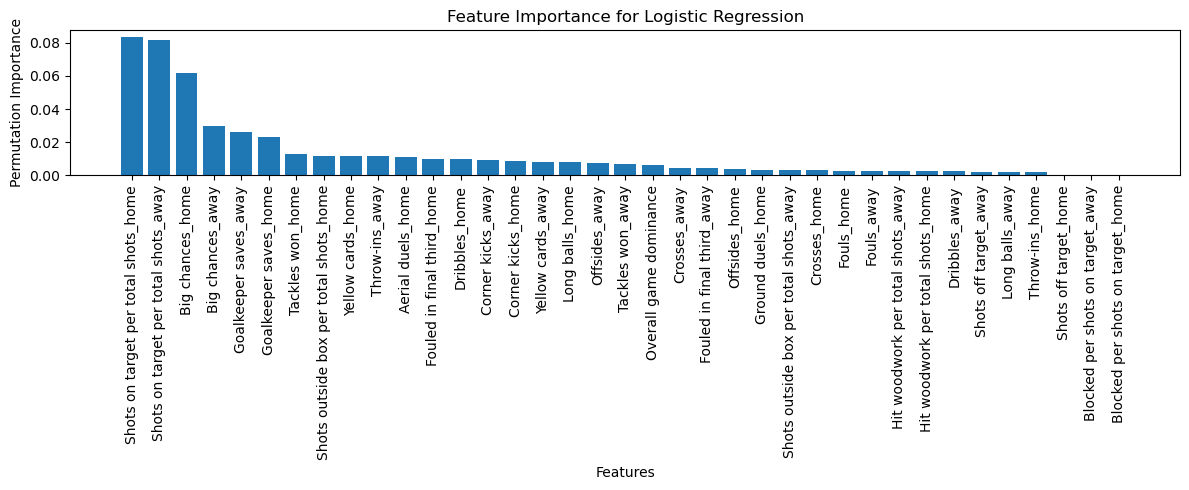

(Pipeline(steps=[('standardscaler', StandardScaler()),
                 ('logisticregression',
                  LogisticRegression(max_iter=1000, multi_class='multinomial'))]),
 array(['Shots on target per total shots_home',
        'Shots on target per total shots_away', 'Big chances_home',
        'Big chances_away', 'Goalkeeper saves_away',
        'Goalkeeper saves_home', 'Tackles won_home',
        'Shots outside box per total shots_home', 'Yellow cards_home',
        'Throw-ins_away', 'Aerial duels_home',
        'Fouled in final third_home', 'Dribbles_home', 'Corner kicks_away',
        'Corner kicks_home', 'Yellow cards_away', 'Long balls_home',
        'Offsides_away', 'Tackles won_away', 'Overall game dominance',
        'Crosses_away', 'Fouled in final third_away', 'Offsides_home',
        'Ground duels_home', 'Shots outside box per total shots_away',
        'Crosses_home', 'Fouls_home', 'Fouls_away',
        'Hit woodwork per total shots_away',
        'Hit woodwork per t

In [11]:
y=merged_df['outcome']
X = merged_df.drop(columns=['date', 'id', 'home_team', 'away_team', 'home_score', 'away_score', 'outcome', 'season'])
mlr(X, y)

Classification Report:
               precision    recall  f1-score   support

        away       0.62      0.72      0.67       218
        draw       0.43      0.18      0.25       159
        home       0.67      0.79      0.73       307

    accuracy                           0.63       684
   macro avg       0.57      0.56      0.55       684
weighted avg       0.60      0.63      0.60       684

Confusion Matrix:
 [[157  14  47]
 [ 56  28  75]
 [ 40  23 244]]


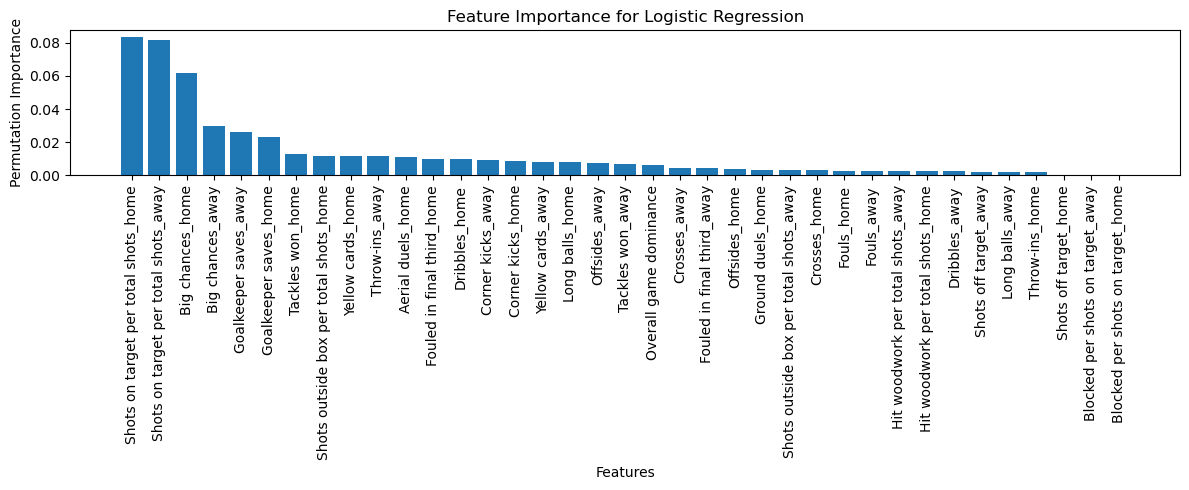

In [13]:
_,imp=mlr(X, y)

In [12]:
rf_classifier(X, y)

Classification Report:
               precision    recall  f1-score   support

        away       0.59      0.68      0.63       218
        draw       0.44      0.09      0.15       159
        home       0.62      0.80      0.70       307

    accuracy                           0.60       684
   macro avg       0.55      0.53      0.49       684
weighted avg       0.57      0.60      0.55       684

Confusion Matrix:
 [[149   8  61]
 [ 53  14  92]
 [ 50  10 247]]


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('randomforestclassifier',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

In [22]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Prepare data
X_np = X.values.astype('float32')
y_enc = LabelEncoder().fit_transform(y)
num_classes = len(set(y_enc))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_np, y_enc, test_size=0.2, stratify=y_enc, random_state=42)

# Standardize
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to tensors
X_train_tensor = torch.tensor(X_train)
y_train_tensor = torch.tensor(y_train)
X_test_tensor = torch.tensor(X_test)
y_test_tensor = torch.tensor(y_test)

# Wrap in DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)


In [23]:
class MatchOutcomeNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(MatchOutcomeNN, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.model(x)

In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MatchOutcomeNN(input_dim=X.shape[1], hidden_dim=64, output_dim=num_classes).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Training loop
for epoch in range(30):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = loss_fn(outputs, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")


Epoch 1, Loss: 84.3709
Epoch 2, Loss: 71.4231
Epoch 3, Loss: 66.4306
Epoch 4, Loss: 63.5770
Epoch 5, Loss: 61.1045
Epoch 6, Loss: 58.6764
Epoch 7, Loss: 56.5632
Epoch 8, Loss: 54.0201
Epoch 9, Loss: 51.7767
Epoch 10, Loss: 50.2980
Epoch 11, Loss: 47.6569
Epoch 12, Loss: 46.0570
Epoch 13, Loss: 43.9304
Epoch 14, Loss: 42.4879
Epoch 15, Loss: 40.8009
Epoch 16, Loss: 39.0283
Epoch 17, Loss: 37.1683
Epoch 18, Loss: 36.2204
Epoch 19, Loss: 34.5399
Epoch 20, Loss: 33.5438
Epoch 21, Loss: 31.8079
Epoch 22, Loss: 30.5499
Epoch 23, Loss: 29.3337
Epoch 24, Loss: 27.9756
Epoch 25, Loss: 27.3234
Epoch 26, Loss: 25.8019
Epoch 27, Loss: 25.1941
Epoch 28, Loss: 24.0026
Epoch 29, Loss: 22.8491
Epoch 30, Loss: 21.7003


In [25]:
from sklearn.metrics import classification_report

model.eval()
all_preds = []
all_true = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(y_batch.numpy())

print(classification_report(all_true, all_preds, target_names=LabelEncoder().fit(y).classes_))


              precision    recall  f1-score   support

        away       0.66      0.72      0.69       218
        draw       0.36      0.36      0.36       159
        home       0.76      0.71      0.74       307

    accuracy                           0.63       684
   macro avg       0.59      0.60      0.59       684
weighted avg       0.64      0.63      0.63       684

